# DreamBooth-LoRA on Stable Diffusion 1.5 with a free T4: rank, training length, and the price of fast inference

**Ashhar Hussain** · ORCID [0009-0009-1568-9852](https://orcid.org/0009-0009-1568-9852)

Part 1 adapts Stable Diffusion 1.5 to one specific subject (five photos of a dog, the `diffusers/dog-example` set) with LoRA on the U-Net attention projections, written as a plain PyTorch training loop on top of `diffusers` and `peft`. Part 2 measures what common inference shortcuts buy on a T4 and what they cost in prompt alignment.

**Questions**

1. How do LoRA rank and the number of training steps trade **subject fidelity** (DINO and CLIP-I similarity to the real photos) against **prompt fidelity** (CLIP-T), the two axes used in the DreamBooth paper? When does the adapter start to overfit?
2. On a T4, how much latency and memory do fp16, faster solvers, LCM-LoRA, a tiny VAE decoder and `torch.compile` save, and how much CLIP score do they give up?

**Run.** Colab → *Runtime → Change runtime type → T4 GPU* → *Run all* (about 35 minutes including downloads). Adapters, results and figures go to `MyDrive/genai-diffusion-lab/sd15/`; *Run all* again after a disconnect skips finished steps.

In [1]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers>=0.32", "peft>=0.14", "transformers", "accelerate"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=False)  # Colab's torchao is older than peft accepts

import json, time, math, copy, random, warnings, contextlib
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from huggingface_hub import snapshot_download
from diffusers import (StableDiffusionPipeline, UNet2DConditionModel, DDPMScheduler, DDIMScheduler,
                       DPMSolverMultistepScheduler, LCMScheduler, AutoencoderTiny)
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
from transformers import CLIPModel, CLIPProcessor, AutoModel, AutoImageProcessor
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=FutureWarning)
GPU = torch.cuda.is_available()
DEVICE = torch.device("cuda" if GPU else "cpu")
SMOKE = os.environ.get("SMOKE") == "1"
MODE = "SMOKE" if SMOKE else ("FULL" if GPU else "CPU")
if MODE == "CPU":
    raise SystemExit("This notebook needs a GPU runtime (T4 is enough).")

OUT = Path("outputs/sd15")
if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive", timeout_ms=60000)
        OUT = Path("/content/drive/MyDrive/genai-diffusion-lab/sd15")
    except Exception as e:  # Drive is optional; without it results stay in this session and in the notebook outputs
        print("Drive not mounted, writing to /content/outputs/sd15:", e)
        OUT = Path("/content/outputs/sd15")
ADAPT, RES, FIG = OUT / "adapters", OUT / "results", OUT / "figures"
for d in (ADAPT, RES, FIG):
    d.mkdir(parents=True, exist_ok=True)

if SMOKE:  # tiny random models, only to exercise the code path on a CPU
    SD, CLIP_ID, DINO_ID, VARIANT, DTYPE = "hf-internal-testing/tiny-sd-pipe", "openai/clip-vit-base-patch32", "facebook/dino-vits16", None, torch.float32
    RANKS, CHECKPOINTS, EVAL_SEEDS, BENCH_PROMPTS, GEN_STEPS = [4], [2, 4], [0], 2, 4
else:
    SD, CLIP_ID, DINO_ID, VARIANT, DTYPE = "stable-diffusion-v1-5/stable-diffusion-v1-5", "openai/clip-vit-large-patch14", "facebook/dino-vits16", "fp16", torch.float16
    RANKS, CHECKPOINTS, EVAL_SEEDS, BENCH_PROMPTS, GEN_STEPS = [4, 32], [100, 250, 500, 1000], [0, 1], 12, 25


def save_json(obj, path):
    tmp = Path(str(path) + ".tmp"); tmp.write_text(json.dumps(obj, indent=2)); tmp.replace(path)


def load_json(path, default=None):
    return json.loads(Path(path).read_text()) if Path(path).exists() else default


def sync():
    if GPU:
        torch.cuda.synchronize()


def amp():
    return torch.autocast("cuda", dtype=torch.float16) if GPU else contextlib.nullcontext()


env = dict(mode=MODE, torch=torch.__version__, gpu=torch.cuda.get_device_name(0) if GPU else None,
           diffusers=__import__("diffusers").__version__, peft=__import__("peft").__version__, model=SD)
save_json(env, RES / "environment.json")
print(env)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'mode': 'FULL', 'torch': '2.14.1+cu130', 'gpu': 'Tesla T4', 'diffusers': '0.42.1', 'peft': '0.21.2', 'model': 'stable-diffusion-v1-5/stable-diffusion-v1-5'}


## Models and data

Stable Diffusion 1.5 in fp16, the five subject photos, and two feature extractors for evaluation: DINO ViT-S/16 (subject fidelity; it separates individual instances of a category better than CLIP, which is why DreamBooth uses it) and CLIP ViT-L/14 (CLIP-I and CLIP-T).

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


resolution 512


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

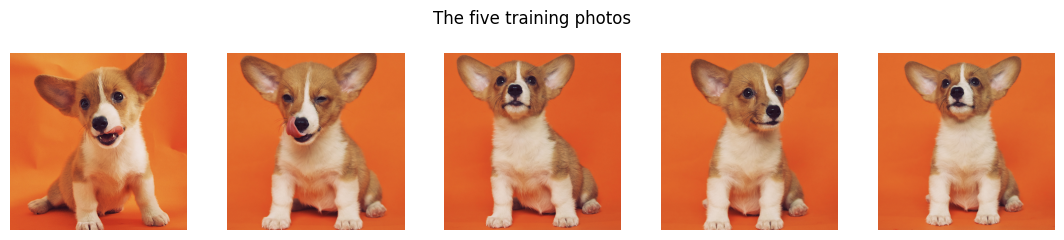

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

In [2]:
pipe = StableDiffusionPipeline.from_pretrained(SD, torch_dtype=DTYPE, variant=VARIANT, safety_checker=None,
                                               requires_safety_checker=False).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
vae, text_encoder, tokenizer = pipe.vae, pipe.text_encoder, pipe.tokenizer
noise_sched = DDPMScheduler.from_pretrained(SD, subfolder="scheduler")
RES_PX = pipe.unet.config.sample_size * pipe.vae_scale_factor
print("resolution", RES_PX)

data_dir = Path(snapshot_download("diffusers/dog-example", repo_type="dataset"))
subject = [Image.open(p).convert("RGB") for p in sorted(data_dir.glob("*.jp*g"))]


def square(img, size):
    w, h = img.size; s = min(w, h)
    img = img.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))
    return img.resize((size, size), Image.BICUBIC)


subject_sq = [square(im, RES_PX) for im in subject]
fig, ax = plt.subplots(1, len(subject_sq), figsize=(2.2 * len(subject_sq), 2.4))
for a, im in zip(np.atleast_1d(ax), subject_sq):
    a.imshow(im); a.axis("off")
fig.suptitle("The five training photos"); plt.tight_layout(); plt.show()

clip = CLIPModel.from_pretrained(CLIP_ID, torch_dtype=DTYPE).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)
dino = AutoModel.from_pretrained(DINO_ID).to(DEVICE).eval()
dino_proc = AutoImageProcessor.from_pretrained(DINO_ID)


def _proj(out):  # transformers 4.x returns a tensor, 5.x an output object with the projection in pooler_output
    return out if isinstance(out, torch.Tensor) else out.pooler_output


@torch.no_grad()
def clip_image_emb(images):
    x = clip_proc(images=images, return_tensors="pt")["pixel_values"].to(DEVICE, DTYPE)
    return F.normalize(_proj(clip.get_image_features(pixel_values=x)).float(), dim=-1)


@torch.no_grad()
def clip_text_emb(texts):
    t = clip_proc(text=texts, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
    return F.normalize(_proj(clip.get_text_features(**t)).float(), dim=-1)


@torch.no_grad()
def dino_emb(images):
    x = dino_proc(images=images, return_tensors="pt")["pixel_values"].to(DEVICE)
    return F.normalize(dino(pixel_values=x).last_hidden_state[:, 0].float(), dim=-1)


REAL_DINO, REAL_CLIP = dino_emb(subject_sq), clip_image_emb(subject_sq)


def score(images, texts):
    d = dino_emb(images) @ REAL_DINO.T
    c = clip_image_emb(images) @ REAL_CLIP.T
    t = (clip_image_emb(images) * clip_text_emb(texts)).sum(-1)
    return dict(dino=d.mean().item(), clip_i=c.mean().item(), clip_t=t.mean().item(),
                clip_t_per_image=t.tolist())

## Part 1: DreamBooth-LoRA

Rare-token identifier `sks`, instance prompt "a photo of sks dog", no prior-preservation images. The VAE latents of the five photos and their horizontal flips, and the text embedding of the prompt, are computed once, so the loop only runs the U-Net. LoRA adapters (rank *r*, alpha = *r*) sit on `to_q`, `to_k`, `to_v` and `to_out.0` of every attention block; the base weights stay in fp16 and the adapter weights in fp32, with fp16 autocast and loss scaling. AdamW, lr 1e-4, batch 1, gradient clipping at 1.0. Every checkpoint is saved to Drive and evaluated on 8 prompts × 2 seeds that place the subject in new contexts (DPM-Solver++, 25 steps, guidance 7.5).

In [3]:
with torch.no_grad():
    px = torch.stack([torch.from_numpy(np.array(im)).permute(2, 0, 1) for im in subject_sq]).float().div(127.5).sub(1)
    px = torch.cat([px, px.flip(-1)]).to(DEVICE, DTYPE)
    dist = vae.encode(px).latent_dist
    LAT_MEAN, LAT_STD = dist.mean, dist.std
    ids = tokenizer("a photo of sks dog", padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt").input_ids.to(DEVICE)
    PROMPT_EMB = text_encoder(ids)[0]
SCALE = vae.config.scaling_factor

TEMPLATES = ["a photo of {} dog on the beach", "a photo of {} dog in the snow", "a photo of {} dog wearing a red hat",
             "a photo of {} dog in a bucket", "a photo of {} dog sleeping on a sofa",
             "a photo of {} dog with a city in the background", "a watercolor painting of {} dog",
             "a photo of {} dog in the jungle"]
if SMOKE:
    TEMPLATES = TEMPLATES[:2]


def dpm(p):
    return DPMSolverMultistepScheduler.from_config(p.scheduler.config, algorithm_type="dpmsolver++")


@torch.no_grad()
def generate(p, prompts, seeds, steps=GEN_STEPS, guidance=7.5, **kw):
    out = []
    for s in seeds:
        for pr in prompts:
            g = torch.Generator(device=DEVICE).manual_seed(s)
            with amp():
                out.append(p(pr, num_inference_steps=steps, guidance_scale=guidance, generator=g,
                             height=RES_PX, width=RES_PX, **kw).images[0])
    return out


exp1_path = RES / "dreambooth_lora.json"
exp1 = load_json(exp1_path, {})

# reference: the base model asked for "a dog" (no identifier), and asked with the untrained identifier
if "base" not in exp1:
    pipe.scheduler = dpm(pipe)
    imgs = generate(pipe, [t.format("a") for t in TEMPLATES], EVAL_SEEDS)
    exp1["base"] = dict(rank=0, step=0, train_s=0, **score(imgs, [t.format("a") for t in TEMPLATES] * len(EVAL_SEEDS)))
    save_json(exp1, exp1_path)


def train_lora(rank):
    tag = f"r{rank}"
    todo = [s for s in CHECKPOINTS if f"{tag}@{s}" not in exp1]
    if not todo:
        print(tag, "done"); return
    unet = UNet2DConditionModel.from_pretrained(SD, subfolder="unet", torch_dtype=DTYPE, variant=VARIANT).to(DEVICE)
    unet.requires_grad_(False)
    unet.add_adapter(LoraConfig(r=rank, lora_alpha=rank, init_lora_weights="gaussian",
                                target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
    for p_ in unet.parameters():
        if p_.requires_grad:
            p_.data = p_.data.float()
    params = [p_ for p_ in unet.parameters() if p_.requires_grad]
    n_params = sum(p_.numel() for p_ in params)
    opt = torch.optim.AdamW(params, lr=1e-4, weight_decay=1e-2)
    scaler = torch.amp.GradScaler("cuda", enabled=GPU)
    start, train_s = 0, 0.0
    state = ADAPT / f"{tag}_state.pt"
    if state.exists():  # resume from the last saved checkpoint
        ck = torch.load(state, map_location=DEVICE)
        for p_, v in zip(params, ck["params"]):
            p_.data.copy_(v)
        opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        start, train_s = ck["step"], ck["train_s"]
        print(f"{tag}: resuming at step {start}")
    g = torch.Generator(device=DEVICE).manual_seed(rank * 1000 + start)
    unet.train()
    sync(); t0 = time.time()
    for step in range(start + 1, max(CHECKPOINTS) + 1):
        i = torch.randint(0, len(LAT_MEAN), (1,), device=DEVICE, generator=g)
        lat = (LAT_MEAN[i] + LAT_STD[i] * torch.randn(LAT_MEAN[i].shape, device=DEVICE, generator=g, dtype=LAT_MEAN.dtype)) * SCALE
        noise = torch.randn(lat.shape, device=DEVICE, generator=g, dtype=lat.dtype)
        t = torch.randint(0, noise_sched.config.num_train_timesteps, (1,), device=DEVICE, generator=g)
        noisy = noise_sched.add_noise(lat, noise, t)
        with amp():
            pred = unet(noisy, t, PROMPT_EMB).sample
        loss = F.mse_loss(pred.float(), noise.float())
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update()
        if step in CHECKPOINTS:
            sync(); train_s += time.time() - t0
            torch.save(dict(params=[p_.detach().clone() for p_ in params], opt=opt.state_dict(), scaler=scaler.state_dict(),
                            step=step, train_s=train_s), state)
            lora_sd = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
            StableDiffusionPipeline.save_lora_weights(ADAPT / f"{tag}_step{step}", unet_lora_layers=lora_sd, safe_serialization=True)
            if f"{tag}@{step}" not in exp1:
                unet.eval()
                ev = StableDiffusionPipeline(vae=vae, text_encoder=text_encoder, tokenizer=tokenizer, unet=unet,
                                             scheduler=dpm(pipe), safety_checker=None, feature_extractor=None,
                                             requires_safety_checker=False)
                ev.set_progress_bar_config(disable=True)
                imgs = generate(ev, [t_.format("sks") for t_ in TEMPLATES], EVAL_SEEDS)
                exp1[f"{tag}@{step}"] = dict(rank=rank, step=step, train_s=train_s, lora_params=n_params,
                                             adapter_mb=n_params * 2 / 2**20,
                                             **score(imgs, [t_.format("a") for t_ in TEMPLATES] * len(EVAL_SEEDS)))
                save_json(exp1, exp1_path)
                if step == max(CHECKPOINTS) or step == CHECKPOINTS[len(CHECKPOINTS) // 2]:
                    fig, ax = plt.subplots(1, len(TEMPLATES), figsize=(2.1 * len(TEMPLATES), 2.5))
                    for a, im, t_ in zip(np.atleast_1d(ax), imgs[:len(TEMPLATES)], TEMPLATES):
                        a.imshow(im); a.axis("off"); a.set_title(t_.format("sks").replace("a photo of ", ""), fontsize=7)
                    fig.suptitle(f"LoRA r={rank}, {step} steps"); plt.tight_layout()
                    fig.savefig(FIG / f"samples_{tag}_step{step}.png", dpi=110); plt.show()
                unet.train()
            print(f"{tag}: step {step}, loss {loss.item():.4f}, {train_s / 60:.1f} min")
            sync(); t0 = time.time()
    del unet, opt
    if GPU:
        torch.cuda.empty_cache()


for r in RANKS:
    train_lora(r)

e1 = pd.DataFrame(exp1.values())
display(e1.drop(columns=["clip_t_per_image"]).round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
b = exp1["base"]
for r in RANKS:
    d = e1[e1["rank"] == r].sort_values("step")
    ax[0].plot(d.step, d.dino, "o-", label=f"DINO, r={r}")
    ax[0].plot(d.step, d.clip_t, "s--", label=f"CLIP-T, r={r}")
    ax[1].plot(d.clip_t, d.dino, "o-", label=f"r={r}")
    for _, row in d.iterrows():
        ax[1].annotate(int(row.step), (row.clip_t, row.dino), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[0].axhline(b["dino"], c="gray", ls=":", lw=1); ax[0].axhline(b["clip_t"], c="gray", ls=":", lw=1)
ax[0].set_xlabel("training steps"); ax[0].set_title("Fidelity over training (dotted: base model)"); ax[0].legend(fontsize=7)
ax[1].scatter([b["clip_t"]], [b["dino"]], c="k", marker="x", label="base model")
ax[1].set_xlabel("CLIP-T (prompt fidelity)"); ax[1].set_ylabel("DINO (subject fidelity)")
ax[1].set_title("Subject vs prompt fidelity"); ax[1].legend(fontsize=8)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); fig.savefig(FIG / "dreambooth_tradeoff.png", dpi=130); plt.show()

Output hidden; open in https://colab.research.google.com to view.

## Part 2: inference cost on a T4

The base model, 12 prompts, one seed each, 512×512. Latency is the median time per image after a warm-up image, with the GPU synchronised; peak memory is `torch.cuda.max_memory_allocated`. Prompt alignment is CLIP-T with ViT-L/14, so every variant is judged on the same images it produced.

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

fp32 · DDIM 50 {'steps': 50, 'batch': 1, 's_per_img': 26.011106133461, 'peak_vram_gb': 7.689282417297363, 'clip_t': 0.282046914100647, 'clip_t_sd': 0.01734325662255287}
fp16 · DDIM 50 {'steps': 50, 'batch': 1, 's_per_img': 8.93498420715332, 'peak_vram_gb': 3.7860398292541504, 'clip_t': 0.2814078629016876, 'clip_t_sd': 0.017297953367233276}
fp16 · DPM-Solver++ 25 {'steps': 25, 'batch': 1, 's_per_img': 4.605300664901733, 'peak_vram_gb': 3.7861008644104004, 'clip_t': 0.2831537127494812, 'clip_t_sd': 0.018273640424013138}
fp16 · DPM-Solver++ 15 {'steps': 15, 'batch': 1, 's_per_img': 2.817172646522522, 'peak_vram_gb': 3.7861008644104004, 'clip_t': 0.28196269273757935, 'clip_t_sd': 0.018882937729358673}
fp16 · DPM-Solver++ 8 {'steps': 8, 'batch': 1, 's_per_img': 1.624645709991455, 'peak_vram_gb': 3.7861008644104004, 'clip_t': 0.28896838426589966, 'clip_t_sd': 0.017320068553090096}


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


... (7 outputs left out)

fp16 · LCM-LoRA 4 {'steps': 4, 'batch': 1, 's_per_img': 0.799030065536499, 'peak_vram_gb': 3.91552734375, 'clip_t': 0.26324185729026794, 'clip_t_sd': 0.023140044882893562}
fp16 · LCM-LoRA 8 {'steps': 8, 'batch': 1, 's_per_img': 1.3330155611038208, 'peak_vram_gb': 3.91552734375, 'clip_t': 0.25621768832206726, 'clip_t_sd': 0.022204482927918434}
fp16 · DPM 25 · batch 4 {'steps': 25, 'batch': 4, 's_per_img': 4.228905498981476, 'peak_vram_gb': 6.441765785217285, 'clip_t': 0.28361284732818604, 'clip_t_sd': 0.018867596983909607}
fp16 · DPM 25 · batch 4 + VAE & attention slicing {'steps': 25, 'batch': 4, 's_per_img': 6.796958267688751, 'peak_vram_gb': 3.793592929840088, 'clip_t': 0.28357556462287903, 'clip_t_sd': 0.0187971368432045}


W1124 22:49:51.289000 7439 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


fp16 · DPM-Solver++ 25 + torch.compile {'steps': 25, 'batch': 1, 's_per_img': 3.099115252494812, 'peak_vram_gb': 3.787398338317871, 'clip_t': 0.282828688621521, 'clip_t_sd': 0.018209630623459816}


,steps,batch,s_per_img,peak_vram_gb,clip_t,clip_t_sd,compile_s,speed-up
fp32 · DDIM 50,50,1,26.011106,7.689282,0.282047,0.017343,NaN,1.000000
fp16 · DDIM 50,50,1,8.934984,3.78604,0.281408,0.017298,NaN,2.911153
fp16 · DPM-Solver++ 25,25,1,4.605301,3.786101,0.283154,0.018274,NaN,5.648080
fp16 · DPM-Solver++ 15,15,1,2.817173,3.786101,0.281963,0.018883,NaN,9.233054
fp16 · DPM-Solver++ 8,8,1,1.624646,3.786101,0.288968,0.01732,NaN,16.010325
fp16 · DPM-Solver++ 25 + TAESD,25,1,4.255036,3.131934,0.281232,0.019161,NaN,6.113017
fp16 · LCM-LoRA 4,4,1,0.79903,3.915527,0.263242,0.02314,NaN,32.553351
fp16 · LCM-LoRA 8,8,1,1.333016,3.915527,0.256218,0.022204,NaN,19.512980
fp16 · DPM 25 · batch 4,25,4,4.228905,6.441766,0.283613,0.018868,NaN,6.150789
fp16 · DPM 25 · batch 4 + VAE & attention slicing,25,4,6.796958,3.793593,0.283576,0.018797,NaN,3.826874


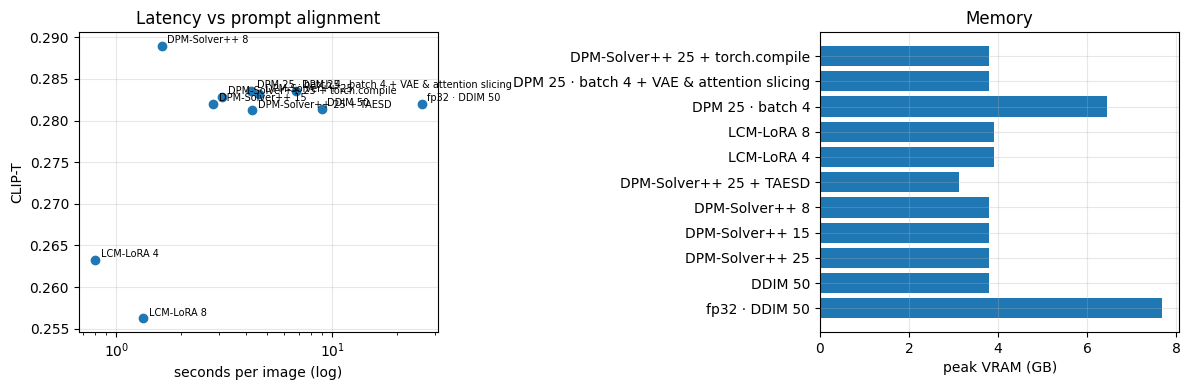

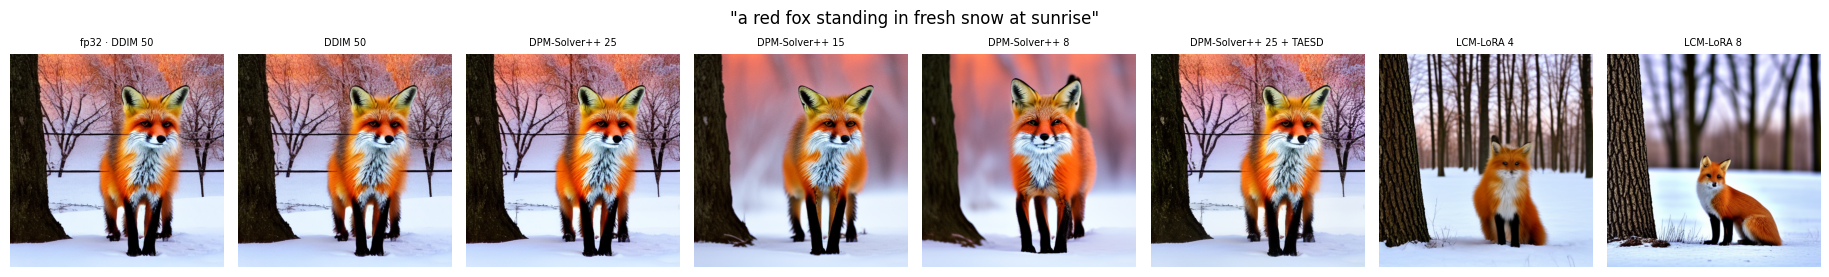

In [4]:
BENCH = ["a red fox standing in fresh snow at sunrise", "a bowl of ramen on a wooden table, studio lighting",
         "an old lighthouse on a rocky coast during a storm", "a portrait of an elderly fisherman, natural light",
         "a modern living room with large windows and plants", "a vintage bicycle leaning against a brick wall",
         "a mountain lake reflecting pine trees at dusk", "a glass of iced coffee on a cafe terrace",
         "a hummingbird hovering near a purple flower", "a busy night market with lanterns",
         "a sailboat on a calm sea under a pink sky", "a stack of pancakes with berries and syrup"][:BENCH_PROMPTS]

exp2_path = RES / "inference_benchmark.json"
exp2 = load_json(exp2_path, {})


def run_variant(name, p, steps, guidance=7.5, batch=1, **kw):
    if name in exp2:
        return
    try:
        generate(p, BENCH[:1], [0], steps=steps, guidance=guidance, **kw)  # warm-up
        if GPU:
            torch.cuda.reset_peak_memory_stats()
        times, imgs = [], []
        for pr in BENCH:
            g = torch.Generator(device=DEVICE).manual_seed(0)
            sync(); t0 = time.time()
            with amp():
                out = p([pr] * batch, num_inference_steps=steps, guidance_scale=guidance, generator=g,
                        height=RES_PX, width=RES_PX, **kw).images
            sync(); times.append((time.time() - t0) / batch)
            imgs.append(out[0])
        t = (clip_image_emb(imgs) * clip_text_emb(BENCH)).sum(-1)
        exp2[name] = dict(steps=steps, batch=batch, s_per_img=float(np.median(times)),
                          peak_vram_gb=torch.cuda.max_memory_allocated() / 2**30 if GPU else None,
                          clip_t=t.mean().item(), clip_t_sd=t.std().item(), clip_t_per_image=t.tolist())
        imgs[0].save(FIG / f"bench_{name.replace(' ', '_').replace('·', '').replace('+', 'plus').replace('/', '_')}.png")
    except Exception as e:
        exp2[name] = dict(error=repr(e)[:300])
    save_json(exp2, exp2_path)
    print(name, {k: v for k, v in exp2[name].items() if k != "clip_t_per_image"})


# fp32 reference
if "fp32 · DDIM 50" not in exp2 and not SMOKE:
    p32 = StableDiffusionPipeline.from_pretrained(SD, torch_dtype=torch.float32, safety_checker=None,
                                                  requires_safety_checker=False).to(DEVICE)
    p32.set_progress_bar_config(disable=True)
    p32.scheduler = DDIMScheduler.from_config(p32.scheduler.config)
    with contextlib.nullcontext():
        amp_backup = amp
        amp = lambda: contextlib.nullcontext()  # true fp32: no autocast
        run_variant("fp32 · DDIM 50", p32, 50)
        amp = amp_backup
    del p32
    if GPU:
        torch.cuda.empty_cache()

pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
run_variant("fp16 · DDIM 50", pipe, 50 if not SMOKE else 4)
pipe.scheduler = dpm(pipe)
run_variant("fp16 · DPM-Solver++ 25", pipe, 25 if not SMOKE else 4)
run_variant("fp16 · DPM-Solver++ 15", pipe, 15 if not SMOKE else 3)
run_variant("fp16 · DPM-Solver++ 8", pipe, 8 if not SMOKE else 2)

# tiny VAE decoder (TAESD) in place of the full VAE decoder
full_vae = pipe.vae
try:
    pipe.vae = AutoencoderTiny.from_pretrained("madebyollin/taesd", torch_dtype=DTYPE).to(DEVICE)
    run_variant("fp16 · DPM-Solver++ 25 + TAESD", pipe, 25 if not SMOKE else 4)
finally:
    pipe.vae = full_vae

# LCM-LoRA: a distilled adapter for 4-step sampling with little or no guidance
if not SMOKE:
    try:
        pipe.load_lora_weights("latent-consistency/lcm-lora-sdv1-5", adapter_name="lcm")
        sched_backup = pipe.scheduler
        pipe.scheduler = LCMScheduler.from_config(pipe.scheduler.config)
        run_variant("fp16 · LCM-LoRA 4", pipe, 4, guidance=1.0)
        run_variant("fp16 · LCM-LoRA 8", pipe, 8, guidance=1.0)
    finally:
        pipe.unload_lora_weights()
        pipe.scheduler = dpm(pipe)

# memory options at batch 4
run_variant("fp16 · DPM 25 · batch 4", pipe, 25 if not SMOKE else 3, batch=4)
def slicing(on):  # newer diffusers moved VAE slicing onto the VAE itself
    (pipe.vae.enable_slicing if on else pipe.vae.disable_slicing)()
    if hasattr(pipe, "enable_attention_slicing"):
        (pipe.enable_attention_slicing if on else pipe.disable_attention_slicing)()


slicing(True)
run_variant("fp16 · DPM 25 · batch 4 + VAE & attention slicing", pipe, 25 if not SMOKE else 3, batch=4)
slicing(False)

# torch.compile on the U-Net (compile time reported separately)
if "fp16 · DPM-Solver++ 25 + torch.compile" not in exp2 and GPU:
    unet_eager = pipe.unet
    try:
        pipe.unet.to(memory_format=torch.channels_last)
        pipe.unet = torch.compile(pipe.unet, mode="max-autotune-no-cudagraphs", fullgraph=False)
        sync(); t0 = time.time()
        generate(pipe, BENCH[:1], [0], steps=25)
        sync(); compile_s = time.time() - t0
        run_variant("fp16 · DPM-Solver++ 25 + torch.compile", pipe, 25)
        if "error" not in exp2["fp16 · DPM-Solver++ 25 + torch.compile"]:
            exp2["fp16 · DPM-Solver++ 25 + torch.compile"]["compile_s"] = compile_s
            save_json(exp2, exp2_path)
    finally:
        pipe.unet = unet_eager

e2 = pd.DataFrame(exp2).T
cols = [c for c in ["steps", "batch", "s_per_img", "peak_vram_gb", "clip_t", "clip_t_sd", "compile_s", "error"] if c in e2]
e2 = e2[cols]
ref_name = "fp32 · DDIM 50" if "fp32 · DDIM 50" in e2.index and "s_per_img" in e2 and pd.notna(e2.loc["fp32 · DDIM 50", "s_per_img"]) else "fp16 · DDIM 50"
e2["speed-up"] = e2["s_per_img"].astype(float).rdiv(float(e2.loc[ref_name, "s_per_img"]))
display(e2)

ok = e2[e2["s_per_img"].notna()] if "s_per_img" in e2 else e2.iloc[:0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(ok.s_per_img.astype(float), ok.clip_t.astype(float))
for n_, row in ok.iterrows():
    ax[0].annotate(n_.replace("fp16 · ", ""), (float(row.s_per_img), float(row.clip_t)), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax[0].set_xscale("log"); ax[0].set_xlabel("seconds per image (log)"); ax[0].set_ylabel("CLIP-T"); ax[0].set_title("Latency vs prompt alignment")
mem = ok[ok.peak_vram_gb.notna()] if "peak_vram_gb" in ok else ok.iloc[:0]
ax[1].barh([n_.replace("fp16 · ", "") for n_ in mem.index], mem.peak_vram_gb.astype(float))
ax[1].set_xlabel("peak VRAM (GB)"); ax[1].set_title("Memory")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); fig.savefig(FIG / "inference_tradeoff.png", dpi=130); plt.show()

# same prompt across variants
shots = [(n_, FIG / f"bench_{n_.replace(' ', '_').replace('·', '').replace('+', 'plus').replace('/', '_')}.png") for n_ in ok.index]
shots = [(n_, p_) for n_, p_ in shots if p_.exists()][:8]
if shots:
    fig, ax = plt.subplots(1, len(shots), figsize=(2.3 * len(shots), 2.8))
    for a, (n_, p_) in zip(np.atleast_1d(ax), shots):
        a.imshow(Image.open(p_)); a.axis("off"); a.set_title(n_.replace("fp16 · ", ""), fontsize=7)
    fig.suptitle(f'"{BENCH[0]}"'); plt.tight_layout(); fig.savefig(FIG / "bench_grid.png", dpi=110); plt.show()

## Findings

Generated from the saved results so the text always matches this run.

In [5]:
from IPython.display import Markdown
from scipy import stats

lines = []
b = exp1["base"]
best = e1[e1["rank"] > 0].copy()
if len(best):
    last = {r: best[best["rank"] == r].sort_values("step").iloc[-1] for r in RANKS}
    first = {r: best[best["rank"] == r].sort_values("step").iloc[0] for r in RANKS}
    peak = {r: best[best["rank"] == r].sort_values("dino").iloc[-1] for r in RANKS}
    lines.append(f"**Setup.** {env['gpu']}; SD 1.5 fp16; LoRA on attention projections; "
                 f"{len(TEMPLATES)} prompts × {len(EVAL_SEEDS)} seeds per checkpoint.")
    lines.append(f"**1. DreamBooth-LoRA.** Base model (generic 'a dog'): DINO {b['dino']:.3f}, CLIP-T {b['clip_t']:.3f}. " + " ".join(
        f"r={r}: DINO {first[r].dino:.3f} → {last[r].dino:.3f} and CLIP-T {first[r].clip_t:.3f} → {last[r].clip_t:.3f} "
        f"from {int(first[r].step)} to {int(last[r].step)} steps (peak DINO {peak[r].dino:.3f} at {int(peak[r].step)} steps; "
        f"{last[r].lora_params / 1e6:.2f} M adapter parameters, {last[r].adapter_mb:.1f} MB in fp16, {last[r].train_s / 60:.1f} min)."
        for r in RANKS))
if len(ok):
    fast = ok.astype({"s_per_img": float}).sort_values("s_per_img")
    ref = ok.loc[ref_name]
    lines.append(f"**2. Inference on the T4.** Reference {ref_name}: {float(ref.s_per_img):.2f} s/image, CLIP-T {float(ref.clip_t):.3f}. " + "; ".join(
        f"{n_}: {float(r_.s_per_img):.2f} s ({float(e2.loc[n_, 'speed-up']):.1f}x), CLIP-T {float(r_.clip_t):.3f}" for n_, r_ in fast.iterrows() if n_ != ref_name))
    ref_t = np.array(exp2[ref_name]["clip_t_per_image"])
    tests = []
    for n_ in fast.index:
        if n_ == ref_name or "clip_t_per_image" not in exp2[n_] or exp2[n_]["batch"] != 1:
            continue
        d = np.array(exp2[n_]["clip_t_per_image"]) - ref_t
        if len(d) > 2 and np.any(d != 0):
            tests.append(f"{n_} {d.mean():+.3f} (Wilcoxon p = {stats.wilcoxon(d).pvalue:.3f})")
    if tests:
        lines.append("Paired CLIP-T difference vs the reference on the same prompts: " + "; ".join(tests) + ".")
md = "\n\n".join(lines)
(RES / "findings.md").write_text(md)
save_json(dict(env=env, dreambooth=e1.drop(columns=["clip_t_per_image"]).to_dict("records"),
               inference=e2.drop(columns=[c for c in ["error"] if c in e2]).reset_index().to_dict("records")), RES / "summary.json")
display(Markdown(md))

**Setup.** Tesla T4; SD 1.5 fp16; LoRA on attention projections; 8 prompts × 2 seeds per checkpoint.

**1. DreamBooth-LoRA.** Base model (generic 'a dog'): DINO 0.273, CLIP-T 0.278. r=4: DINO 0.550 → 0.695 and CLIP-T 0.283 → 0.248 from 100 to 1000 steps (peak DINO 0.695 at 1000 steps; 0.80 M adapter parameters, 1.5 MB in fp16, 4.9 min). r=32: DINO 0.617 → 0.805 and CLIP-T 0.275 → 0.225 from 100 to 1000 steps (peak DINO 0.805 at 1000 steps; 6.38 M adapter parameters, 12.2 MB in fp16, 4.7 min).

**2. Inference on the T4.** Reference fp32 · DDIM 50: 26.01 s/image, CLIP-T 0.282. fp16 · LCM-LoRA 4: 0.80 s (32.6x), CLIP-T 0.263; fp16 · LCM-LoRA 8: 1.33 s (19.5x), CLIP-T 0.256; fp16 · DPM-Solver++ 8: 1.62 s (16.0x), CLIP-T 0.289; fp16 · DPM-Solver++ 15: 2.82 s (9.2x), CLIP-T 0.282; fp16 · DPM-Solver++ 25 + torch.compile: 3.10 s (8.4x), CLIP-T 0.283; fp16 · DPM 25 · batch 4: 4.23 s (6.2x), CLIP-T 0.284; fp16 · DPM-Solver++ 25 + TAESD: 4.26 s (6.1x), CLIP-T 0.281; fp16 · DPM-Solver++ 25: 4.61 s (5.6x), CLIP-T 0.283; fp16 · DPM 25 · batch 4 + VAE & attention slicing: 6.80 s (3.8x), CLIP-T 0.284; fp16 · DDIM 50: 8.93 s (2.9x), CLIP-T 0.281

Paired CLIP-T difference vs the reference on the same prompts: fp16 · LCM-LoRA 4 -0.019 (Wilcoxon p = 0.027); fp16 · LCM-LoRA 8 -0.026 (Wilcoxon p = 0.001); fp16 · DPM-Solver++ 8 +0.007 (Wilcoxon p = 0.151); fp16 · DPM-Solver++ 15 -0.000 (Wilcoxon p = 0.850); fp16 · DPM-Solver++ 25 + torch.compile +0.001 (Wilcoxon p = 0.850); fp16 · DPM-Solver++ 25 + TAESD -0.001 (Wilcoxon p = 0.970); fp16 · DPM-Solver++ 25 +0.001 (Wilcoxon p = 0.791); fp16 · DDIM 50 -0.001 (Wilcoxon p = 0.064).

### Limitations

* One subject and eight evaluation prompts; DreamBooth evaluates 30 subjects with 25 prompts each, so the curves show the shape of the trade-off rather than general constants.
* CLIP-T and DINO are proxies for human judgement; no user study.
* No prior-preservation loss, so the adapter is free to drift on the class "dog" as a whole.
* Latency on a shared Colab T4 varies between sessions by a few percent; ratios between variants are more stable than absolute times.

### References

Rombach et al. (2022) *High-Resolution Image Synthesis with Latent Diffusion Models* · Ruiz et al. (2023) *DreamBooth* · Hu et al. (2022) *LoRA* · Lu et al. (2022) *DPM-Solver++* · Song et al. (2021) *DDIM* · Luo et al. (2023) *LCM-LoRA: A Universal Stable-Diffusion Acceleration Module* · Caron et al. (2021) *Emerging Properties in Self-Supervised Vision Transformers (DINO)* · Radford et al. (2021) *CLIP* · Hessel et al. (2021) *CLIPScore*